# Non-Linear Models


## Setup
If needed, uncomment and run the installation line once. Restart the kernel after installation if requested. `palmerpenguins` includes the data, so loading it does not require a separate data download.

In [ ]:
import numpy as np
import pandas as pd
from pickle import TRUE
import statsmodels.formula.api as smf
import statsmodels.api as sm
from plotnine import *
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from patsy import dmatrix, build_design_matrices



### Data Generation

In [ ]:

# Use one random-number generator so every simulated dataset is reproducible.
rng = np.random.default_rng(123)


def simulate_quartic_data(n=1000, x_sd=0.25, noise_sd=0.5):
    """Simulate data from the quartic relationship used in the slides."""
    x = rng.normal(loc=0, scale=x_sd, size=n)
    y = (
        1
        + 5.3 * x
        - 45 * x**2
        - 35.5 * x**3
        + 60 * x**4
        + rng.normal(loc=0, scale=noise_sd, size=n)
    )
    return pd.DataFrame({"x": x, "y": y})


def simulate_quadratic_data(n=1000, x_sd=0.25, noise_sd=0.5):
    """Simulate data from the quadratic relationship used for knot examples."""
    x = rng.normal(loc=0, scale=x_sd, size=n)
    y = 1 + 5.3 * x - 45 * x**2 + rng.normal(loc=0, scale=noise_sd, size=n)
    return pd.DataFrame({"x": x, "y": y})


def simulate_sine_data(n=1000, x_sd=3.5, noise_sd=0.25):
    """Simulate data from the sinusoidal relationship used in the slides."""
    x = rng.normal(loc=0, scale=x_sd, size=n)
    y = 1 + np.sin(np.pi * x / 8) + rng.normal(loc=0, scale=noise_sd, size=n)
    return pd.DataFrame({"x": x, "y": y})


# Each object corresponds to one of the original R simulation chunks.
motivating_polynomial_data = simulate_quartic_data()
motivating_sine_data = simulate_sine_data()
linear_fit_data = simulate_quartic_data()
quartic_fit_data = simulate_quartic_data()
polynomial_example_data = simulate_quartic_data()
step_plot_data = simulate_quartic_data()
step_example_data = simulate_quartic_data()
knot_data = simulate_quadratic_data()
more_knots_data = simulate_quadratic_data()
cubic_spline_data = simulate_quartic_data()
natural_spline_data = simulate_quartic_data()
spline_example_data = simulate_quartic_data()


## Polynomial Regression

### Viewing Data

In [ ]:
motivating_polynomial_data

### Plotting Data

In [ ]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=1.2, alpha=0.65)
    + theme_bw()
)

### Fitting a Line

In [ ]:
linear_model = smf.ols("y ~ x", data=motivating_polynomial_data).fit()

#### Predicting Data

In [ ]:
linear_grid = pd.DataFrame(
    {"x": np.linspace(motivating_polynomial_data["x"].min(), 
                      motivating_polynomial_data["x"].max(), 300)}
)
linear_grid["predicted_y"] = linear_model.predict(linear_grid)

#### Adding Line

In [ ]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=1.2, alpha=0.65)
    + geom_line(
        data=linear_grid,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "blue"
    )
    + theme_bw()
)

### Fitting A Polynomial

In [ ]:
poly_model = smf.ols(
    "y ~ x + I(x ** 2) + I(x ** 3) ",
    data=motivating_polynomial_data,
).fit()



#### Predicting Data

In [162]:
poly_grid = pd.DataFrame(
    {"x": np.linspace(motivating_polynomial_data["x"].min(), 
    motivating_polynomial_data["x"].max(), 300)}
)
poly_grid["predicted_y"] = poly_model.predict(poly_grid)

#### Plotting Models

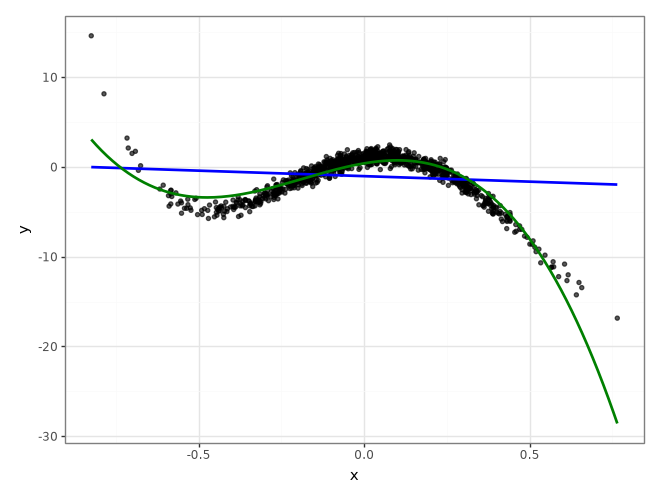

In [163]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=1.2, alpha=0.65)
    + geom_line(
        data=linear_grid,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "blue"
    )
    + geom_line(
        data=poly_grid,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "green"
    )    
    + theme_bw()
)

### Fitting Polynomial (Alternative)

In [164]:
polynomial_alt = PolynomialFeatures(degree=4, include_bias=True)
X_polynomial = polynomial_alt.fit_transform(motivating_polynomial_data[["x"]])
poly_model_alt = sm.OLS(motivating_polynomial_data["y"], X_polynomial).fit()


#### Predicting Model

In [165]:
poly_grid_alt = pd.DataFrame(
    {"x": np.linspace(motivating_polynomial_data["x"].min(), 
    motivating_polynomial_data["x"].max(), 300)}
)
X_poly_alt = polynomial_alt.fit_transform(poly_grid_alt[["x"]])
poly_grid_alt["predicted_y"] = poly_model_alt.predict(X_poly_alt)

#### Plotting Data

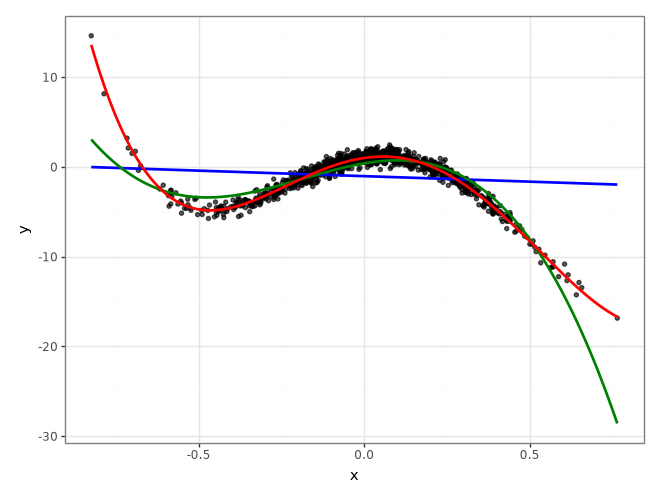

In [166]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=1.2, alpha=0.65)
    + geom_line(
        data=linear_grid,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "blue"
    )
    + geom_line(
        data=poly_grid,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "green"
    )    
    + geom_line(
        data=poly_grid_alt,
        mapping=aes(x="x", y="predicted_y"),
        inherit_aes=False,
        size=1.1,
        color = "red"
    )
    + theme_bw()
)

## Step Functions

### 20 Steps

#### Get Cuts

In [167]:
cut_20, bin_edges = pd.qcut(motivating_polynomial_data["x"], q = 20, retbins=True)

#### Fit Model and Predict


In [168]:

step_model_20 = sm.OLS(motivating_polynomial_data["y"], pd.get_dummies(cut_20)).fit()
step_predictions = step_model_20.params.to_numpy()

step_data_20 = pd.DataFrame({
    "x": bin_edges,
    "predicted_y": np.append(step_predictions, step_predictions[-1])
})


#### Plotting

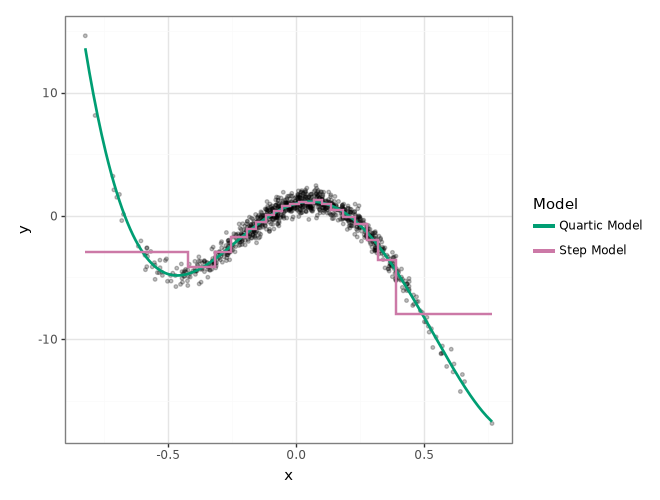

In [169]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=1, alpha=0.25)
    + geom_line(
        data=poly_grid_alt,
        mapping=aes(
            x="x", y="predicted_y", color='"Quartic Model"'
        ),
        inherit_aes=False,
        size=1.1
    )
    + geom_step(
        data=step_data_20,
        mapping=aes(
            x="x", y="predicted_y", color='"Step Model"'
        ),
        inherit_aes=False,
        direction="hv",
        size=1
    )
    + scale_color_manual(
        name="Model",
        values={
            "Linear Model": "#0072B2",
            "Cubic Model": "#D55E00",
            "Quartic Model": "#009E73",
            "Step Model": "#CC79A7"
        },
    )
    + theme_bw()
)

### 60 Cuts

#### Getting Cuts

In [170]:
cut_60, bin_edges = pd.qcut(motivating_polynomial_data["x"], q = 60, retbins=True)

#### Fitting Model and Prediction

In [171]:
step_model_60 = sm.OLS(motivating_polynomial_data["y"], pd.get_dummies(cut_60)).fit()
step_predictions = step_model_60.params.to_numpy()

step_data_60 = pd.DataFrame({
    "x": bin_edges,
    "predicted_y": np.append(step_predictions, step_predictions[-1])
})

#### Plotting

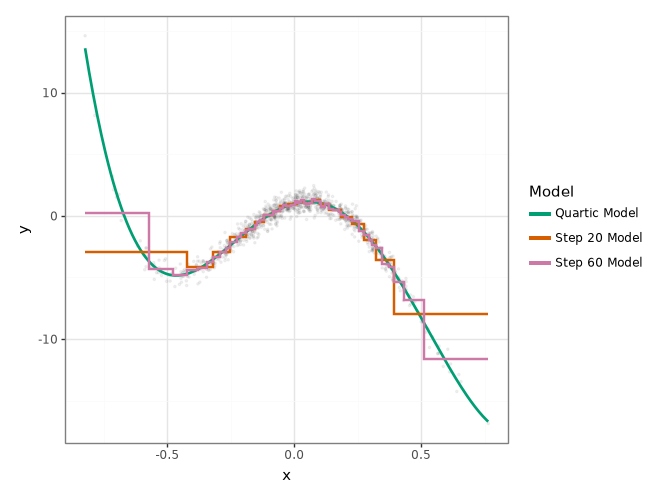

In [172]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=0.5, alpha=0.05)
    + geom_line(
        data=poly_grid_alt,
        mapping=aes(
            x="x", y="predicted_y", color='"Quartic Model"'
        ),
        inherit_aes=False,
        size=1.1
    )
    + geom_step(
        data=step_data_20,
        mapping=aes(
            x="x", y="predicted_y", color='"Step 20 Model"'
        ),
        inherit_aes=False,
        direction="hv",
        size=1
    )
    + geom_step(
        data=step_data_60,
        mapping=aes(
            x="x", y="predicted_y", color='"Step 60 Model"'
        ),
        inherit_aes=False,
        direction="hv",
        size=1
    )
    + scale_color_manual(
        name="Model",
        values={
            "Linear Model": "#0072B2",
            "Step 20 Model": "#D55E00",
            "Quartic Model": "#009E73",
            "Step 60 Model": "#CC79A7"
        },
    )
    + theme_bw()
)

## Regression Splines

### B-Splines

In [173]:
# Create a cubic B-spline basis.
b_spline_X = dmatrix(
    "bs(x, df=5, degree=3, include_intercept=False)",
    data = motivating_polynomial_data,
    return_type = "dataframe"
)

### Fitting Model

In [174]:
bs_model = sm.OLS(motivating_polynomial_data["y"], b_spline_X).fit()

### Predicting Model

In [175]:
bspline_grid = pd.DataFrame(
    {"x": np.linspace(motivating_polynomial_data["x"].min(), 
    motivating_polynomial_data["x"].max(), 300)}
)

bspline_grid_X = build_design_matrices(
    [b_spline_X.design_info],
    bspline_grid
)[0]

bspline_grid["predicted_y"] = bs_model.predict(bspline_grid_X)

### Plottting Model

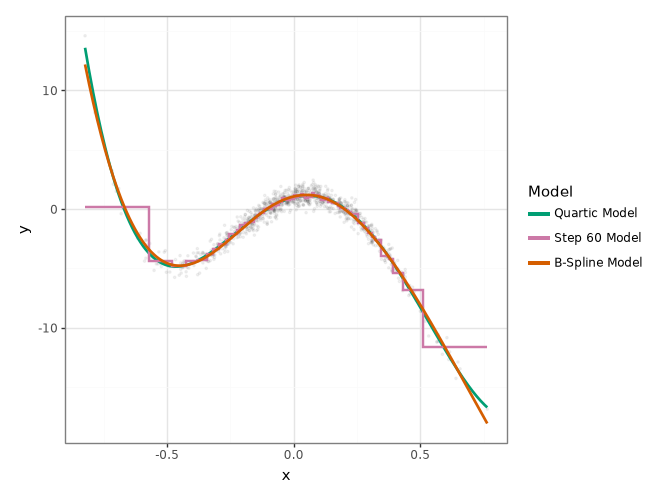

In [176]:
(
    ggplot(motivating_polynomial_data, aes(x="x", y="y"))
    + geom_point(size=0.5, alpha=0.05)
    + geom_line(
        data=poly_grid_alt,
        mapping=aes(
            x="x", y="predicted_y", color='"Quartic Model"'
        ),
        inherit_aes=False,
        size=1.1
    )
    + geom_step(
        data=step_data_60,
        mapping=aes(
            x="x", y="predicted_y", color='"Step 60 Model"'
        ),
        inherit_aes=False,
        direction="hv",
        size=1
    )
    + geom_line(
        data=bspline_grid,
        mapping=aes(
            x="x", y="predicted_y", color='"B-Spline Model"'
        ),
        inherit_aes=False,
        size=1.1
    )
    + scale_color_manual(
        name="Model",
        values={
            "Linear Model": "#0072B2",
            "B-Spline Model": "#D55E00",
            "Quartic Model": "#009E73",
            "Step 60 Model": "#CC79A7"
        },
    )
    + theme_bw()
)